# KITScenes — Labels

Besides the HD maps (notebook 04), the release ships two label products per scene:

- **ground segmentation** for every lidar: one bool per lidar point, `frame.lidar(lidar, labels=True)`;
- **instance masks** of the front and rear ring cameras: Mapillary Vistas classes from a panoptic model (seamseg),
  `frame.instances(camera)`. They are model output, not human annotation.

The test splits withhold labels and maps: that is what the benchmarks evaluate. This notebook shows both products,
how they combine with the lidar, and how to see what a scene has.

**Needs:** `kitscenes[viz]` installed as in the README and a scene of a split with labels (train, val, overlap).
The example scene and how to download it alone: notebook 01.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

import kitscenes

%matplotlib inline
plt.rcParams["figure.dpi"] = 72  # small figures

DATASET_ROOT = os.environ.get("KITSCENES_ROOT", "/data/kitscenes")  # or an absolute path
SCENE_ID = "c34c778f-ad8c-0aa9-7e1a-c86a73f887c7"  # the example scene (notebook 01); any scene UUID on disk works

In [2]:
ds = kitscenes.open(DATASET_ROOT)  # every split under the root
scene = ds[SCENE_ID]
frame = scene[min(50, len(scene) - 1)]
print(scene.info)

SceneInfo(scene_id='c34c778f-ad8c-0aa9-7e1a-c86a73f887c7', split='val', city='Frankfurt', lidar='velodyne', num_frames=220, recording_week='2025-W34', time_of_day='afternoon', light='day', sun_below_horizon=False, dark=False, recording_order=779, drive=11, order_in_drive=258, rig='velodyne_2025', sd_snapshot='Frankfurt_2025-W34.osm.pbf', duration_s=21.9, distance_m=174.0, mean_speed_mps=8.0, max_speed_mps=10.0, road_motorway_share=0.0, road_arterial_share=1.0, road_local_share=0.0, road_service_share=0.0, road_unmatched_share=0.0, road_dominant='arterial', speed_limit_kph_median=50.0, weather='partly_cloudy', road_surface='dry', weather_confidence='high')


## 1. Ground segmentation

`frame.lidar(lidar, labels=True)` adds the labels to the cloud as the bool column `ground` (`cloud["ground"]`), one
per point. `frame.ground_mask(lidar)` gives the same array alone. With `rows=True` both have one entry per stored
row (notebook 02); the label of a row without a point means nothing, and a no-return gets False.

63,807 of 204,558 points are ground; frame.ground_mask gives the same: True


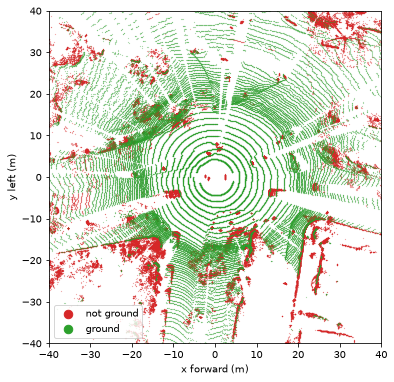

In [3]:
cloud = frame.lidar("lidar_top", labels=True)
xyz, is_ground = cloud.xyz, cloud["ground"]
print(f"{int(is_ground.sum()):,} of {len(cloud):,} points are ground; frame.ground_mask gives the same:",
      np.array_equal(is_ground, frame.ground_mask("lidar_top")))
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*xyz[~is_ground, :2].T, s=0.02, c="tab:red", label="not ground")
ax.scatter(*xyz[is_ground, :2].T, s=0.02, c="tab:green", label="ground")
ax.set(xlim=(-40, 40), ylim=(-40, 40), aspect="equal", xlabel="x forward (m)", ylabel="y left (m)")
ax.legend(markerscale=60)
plt.show()

## 2. Instance masks

`frame.instances(camera)` holds the detections of one image: `classes` (Vistas class IDs), `scores`, `boxes` and
run-length-encoded masks. `label_images()` paints them into a per-pixel class image and an instance-ID image
(`kitscenes.instances.UNLABELLED` where nothing was detected).

InstanceMasks(camera='camera_ring_front', image_size=(3504, 2272), classes=<int64 (79,)>, scores=<float64 (79,)>, boxes=<float64 (79, 4)>, rles=[79 str], provenance='model_derived')
detections: ['Bike Rack', 'Car', 'Crosswalk - Plain', 'Manhole', 'Motorcycle', 'Motorcyclist', 'Other Rider', 'Person', 'Pole', 'Street Light', 'Traffic Light', 'Traffic Sign (Back)', 'Traffic Sign (Front)', 'Trash Can', 'Utility Pole']


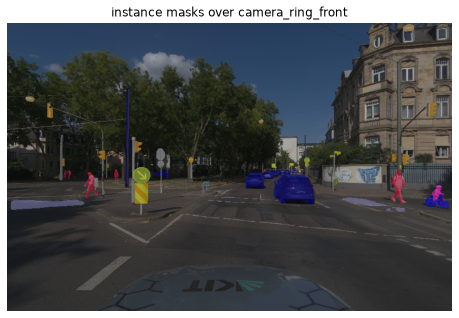

In [4]:
from kitscenes.instances import CLASS_NAMES, UNLABELLED, VISTAS_CLASSES

masks = frame.instances("camera_ring_front")
print(masks)
print("detections:", sorted(set(masks.names())))
classes, instance_ids = masks.label_images()

palette = np.zeros((256, 3), np.uint8)
for train_id, _, _, rgb in VISTAS_CLASSES:
    palette[train_id] = rgb
image = frame.image("camera_ring_front")
overlay = np.where((classes != UNLABELLED)[..., None], 0.5 * image + 0.5 * palette[classes], image).astype(np.uint8)
plt.figure(figsize=(8, 5.2))
plt.imshow(overlay[::4, ::4])
plt.title("instance masks over camera_ring_front")
plt.axis("off")
plt.show()

## 3. Labels on lidar points

`kitscenes.painting` projects lidar points into the ring cameras and reads out the colour (`paint`) or the instance
class (`label`): a quick way to get semantic lidar points from the camera labels. It does not check what a camera can
see, so a point hidden behind something nearer takes the colour and class of what is in front of it.

45,373 of 710,179 points got a class from the cameras
[('Car', 22808), ('Pole', 7808), ('Traffic Sign (Front)', 4835), ('Traffic Sign (Back)', 2915), ('Traffic Light', 1888), ('Person', 1524), ('Crosswalk - Plain', 969), ('Utility Pole', 921)]


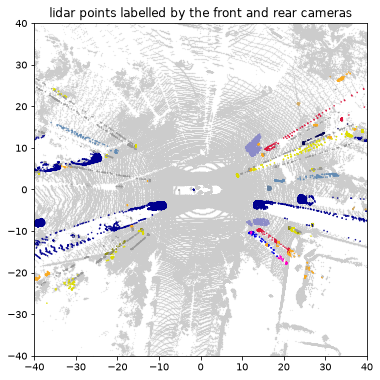

In [5]:
from kitscenes.painting import label

xyz = frame.fused_lidar().xyz
classes, instance, camera = label(frame, xyz)
seen = classes != UNLABELLED
print(f"{seen.sum():,} of {len(xyz):,} points got a class from the cameras")
from collections import Counter

print(Counter(CLASS_NAMES[int(c)] for c in classes[seen]).most_common(8))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*xyz[~seen, :2].T, s=0.02, c="0.8")
ax.scatter(*xyz[seen, :2].T, s=0.3, c=palette[classes[seen]] / 255)
ax.set(xlim=(-40, 40), ylim=(-40, 40), aspect="equal", title="lidar points labelled by the front and rear cameras")
plt.show()

## 4. What a scene has: availability and the test splits

`scene.availability(what, index)` / `frame.availability(what)` answer without reading the data: for a sensor name,
`"ground_labels/<lidar>"`, `"instances/<camera>"`, `"map"`, `"pose"`, `"aerial"` or `"<gnss device>/<topic>"`. The split
decides what is withheld (`kitscenes.SPLITS`): the test splits ship no maps and no labels, and in the test-e2e splits
the poses are relative to the first pose instead of the map frame. The table below has a row per split on disk:
with only the example scene that is val, and the cell after it finds no test split.
`kitscenes download "$KITSCENES_ROOT" --splits test --components none --no-aerial` adds the small files of every
test scene (about 4 GB).

In [6]:
print(f"{'split':30s} {'maps':>5s} {'labels':>6s}  poses")
for name, info in kitscenes.SPLITS.items():
    print(f"{name:30s} {str(info.has_maps):>5s} {str(info.has_labels):>6s}  {info.pose_frame}")

split                           maps labels  poses
train                           True   True  local_utm
val                             True   True  local_utm
test                           False  False  local_utm
test-e2e                       False  False  first_pose
overlap_train_val               True   True  local_utm
map_change_train                True   True  local_utm
map_change_val                  True   True  local_utm
map_change_test                False  False  local_utm
map_change_test-e2e            False  False  first_pose
map_change_overlap_train_val    True   True  local_utm


In [7]:
what = ["lidar_top", "ground_labels/lidar_top", "instances/camera_ring_front", "map", "pose"]
print(f"{'split':30s}" + "".join(f"{w.split('/')[0]:>19s}" for w in what))
for split in [name for name in ds.splits if name in kitscenes.SPLITS]:
    s = ds.filter(splits=split)[0]
    print(f"{split:30s}" + "".join(f"{s.availability(w, 0).value:>19s}" for w in what))

split                                   lidar_top      ground_labels          instances                map               pose
val                                       present            present            present            present            present


In a test split, the accessors raise with state `WITHHELD_BY_SPLIT` (or return None with `missing="none"`), and a
training sample made with `SampleSpec(require=False)` says so in `sample["map"]["state"]` instead of raising:

In [8]:
test_splits = [s for s in ds.splits if s in kitscenes.SPLITS and not kitscenes.SPLITS[s].has_labels]
if test_splits:
    test_frame = ds.filter(splits=test_splits[0])[0][10]
    try:
        test_frame.ground_mask("lidar_top")
    except kitscenes.LabelsUnavailable as err:
        print(f"{test_splits[0]}: {err}")
    print("map:", test_frame.scene.availability("map").value, "| pose frame:", test_frame.scene.pose_frame)
else:
    print("no test split downloaded")

no test split downloaded
